# Proyecto Parcial I: Predicción del rendimiento académico con aprendizaje automático
**Universidad de Guayaquil — Carrera de Ciencia de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 | **Grupo:** E | **Fecha:** 25 de noviembre de 2026

**Integrantes:**
- Granda Zambrano Cecilia Lorena
- Almeida Terry
- Campoverde María Fernanda
- Molina Sarco Juan
- Núñez Katherine

**Dataset:** Student Performance, Matemáticas (`student-mat.csv`), Cortez y Silva (2008).

**Preguntas:** (1) ¿Qué nota final obtendrá un estudiante? (2) ¿Aprobará o reprobará?

---
**Archivo independiente:** Parte3 Regresion Lineal

In [1]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
import statsmodels.api as sm

SEED = 2026  # semilla del grupo (justificación en la Parte 2.5)

In [2]:
# Carga del dataset: funciona en Google Colab, en el PC, en GitHub Codespaces y en GitHub Actions
ARCHIVO = 'student-mat.csv'
rutas = [ARCHIVO, os.path.join('data', ARCHIVO)]
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    try:                      # solo existe en Google Colab
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Copie {ARCHIVO} en la misma carpeta del notebook.')
    print(f'Seleccione el archivo {ARCHIVO}')
    subido = files.upload()
    ruta = next(iter(subido))

df = pd.read_csv(ruta, sep=None, engine='python')  # detecta separador ',' o ';'
assert df.shape[1] == 33, 'El archivo no es el student-mat.csv esperado (33 columnas).'
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Preparación (necesaria para ejecutar esta parte sola)
El detalle y las justificaciones están en la Parte 2.

In [3]:
# Tipos de variables
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

In [4]:
# 2.1 Faltantes y duplicados en el dataset original
print('Faltantes originales:', df.isnull().sum().sum())
print('Filas duplicadas    :', df.duplicated().sum())

# Introducir 5 % de faltantes al azar (sobre una copia, para no alterar el EDA)
datos = df.copy()
rng = np.random.default_rng(SEED)
n_nan = int(round(0.05 * len(datos)))
for col in ['absences', 'studytime']:
    datos[col] = datos[col].astype(float)
    datos.loc[rng.choice(datos.index, size=n_nan, replace=False), col] = np.nan
print(datos[['absences', 'studytime']].isnull().sum())
print((datos[['absences', 'studytime']].isnull().mean() * 100).round(2))
print(df[['absences', 'studytime']].agg(['mean', 'median', 'skew']).round(2))

Faltantes originales: 0
Filas duplicadas    : 0
absences     20
studytime    20
dtype: int64
absences     5.06
studytime    5.06
dtype: float64
        absences  studytime
mean        5.71       2.04
median      4.00       2.00
skew        3.67       0.63


In [5]:
# Variable objetivo de clasificación (Parte 4.1)
datos['aprueba'] = (datos['G3'] >= 10).astype(int)

# 2.5 División 80/20. Se usa la MISMA partición para todos los modelos.
train, test = train_test_split(datos, test_size=0.20, random_state=SEED)
print(f'Entrenamiento: {len(train)} | Prueba: {len(test)}')

Entrenamiento: 316 | Prueba: 79


In [6]:
# 2.3 y 2.4 Preprocesamiento dentro de Pipeline + ColumnTransformer
feat_A = [c for c in df.columns if c != 'G3']                 # incluye G1 y G2
feat_B = [c for c in feat_A if c not in ['G1', 'G2']]         # sin G1 ni G2

def crear_pipeline(features, modelo):
    """Imputa, escala y codifica. Todo se ajusta solo con los datos de entrenamiento."""
    nums = [c for c in features if c in num_cols]
    cats = [c for c in features if c in cat_cols]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), nums),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          # drop='first' evita la multicolinealidad perfecta entre dummies
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cats)
    ], sparse_threshold=0)
    return Pipeline([('preprocessor', prep), ('model', modelo)])

y_train, y_test = train['G3'], test['G3']

## Parte 3. Regresión lineal múltiple
### 3.1 y 3.2 Modelos y métricas

,Modelo,MSE,RMSE,R2,R2 train
0,"A (con G1, G2)",3.2969,1.8157,0.8250,0.8453
1,"B (sin G1, G2)",18.1722,4.2629,0.0357,0.3050


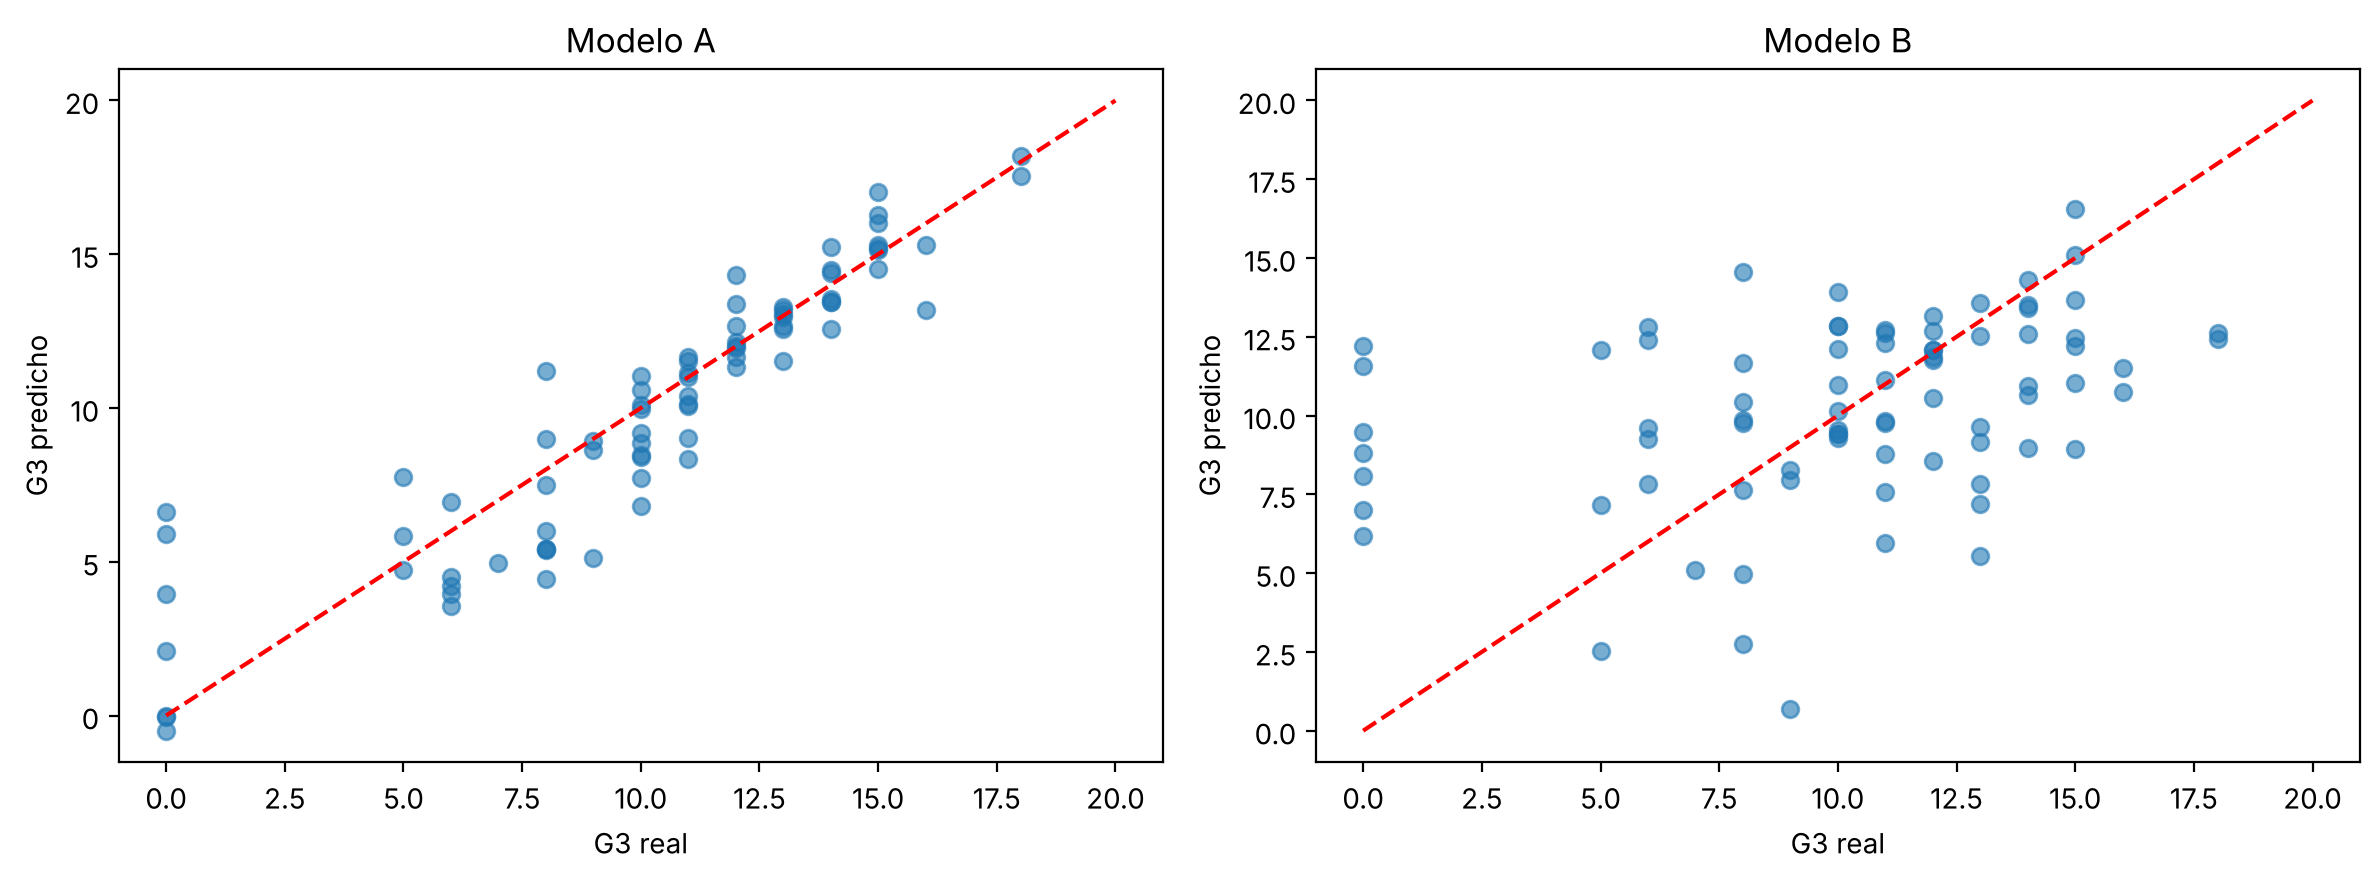

In [7]:
# 3.1 y 3.2 Modelos A y B
modelos, preds, filas = {}, {}, []
for nombre, feats in [('A (con G1, G2)', feat_A), ('B (sin G1, G2)', feat_B)]:
    m = crear_pipeline(feats, LinearRegression()).fit(train[feats], y_train)
    p = m.predict(test[feats])
    mse = mean_squared_error(y_test, p)
    modelos[nombre[0]], preds[nombre[0]] = m, p
    filas.append({'Modelo': nombre, 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_test, p),
                  'R2 train': m.score(train[feats], y_train)})
tabla_lin = pd.DataFrame(filas).round(4)
display(tabla_lin)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, k in zip(ax, 'AB'):
    a.scatter(y_test, preds[k], alpha=0.6); a.plot([0, 20], [0, 20], 'r--')
    a.set(title=f'Modelo {k}', xlabel='G3 real', ylabel='G3 predicho')
plt.tight_layout(); plt.show()

- **Modelo A:** R² = 0.825 y RMSE = 1.82. Explica cerca del 82.5 % de la variación de G3 en prueba, con un error típico de unos 1.8 puntos sobre 20.
- **Modelo B:** R² = 0.036 y RMSE = 4.26 (MSE = 18.17). En prueba apenas mejora a predecir la media. El R² de entrenamiento (0.305) es mucho mayor, lo que indica **sobreajuste y poca generalización**. No es adecuado para estimar la nota individual.

El MSE está en puntos al cuadrado y penaliza más los errores grandes. El RMSE vuelve a la escala de la nota.

### 3.3 Cálculo manual

In [8]:
# 3.3 Cálculo manual con NumPy (Modelo B) y comparación con scikit-learn
y = y_test.to_numpy(); y_hat = preds['B']
mse_m = np.mean((y - y_hat) ** 2)
rmse_m = np.sqrt(mse_m)
r2_m = 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)
comp = pd.DataFrame({'NumPy': [mse_m, rmse_m, r2_m],
                     'scikit-learn': [mean_squared_error(y, y_hat), np.sqrt(mean_squared_error(y, y_hat)),
                                      r2_score(y, y_hat)]}, index=['MSE', 'RMSE', 'R2'])
display(comp)
print('¿Coinciden?', np.allclose(comp['NumPy'], comp['scikit-learn']))

,NumPy,scikit-learn
MSE,18.172162,18.172162
RMSE,4.262882,4.262882
R2,0.035690,0.035690


¿Coinciden? True


El cálculo con NumPy coincide con scikit-learn.

### 3.4 Los cinco supuestos (Modelo B)

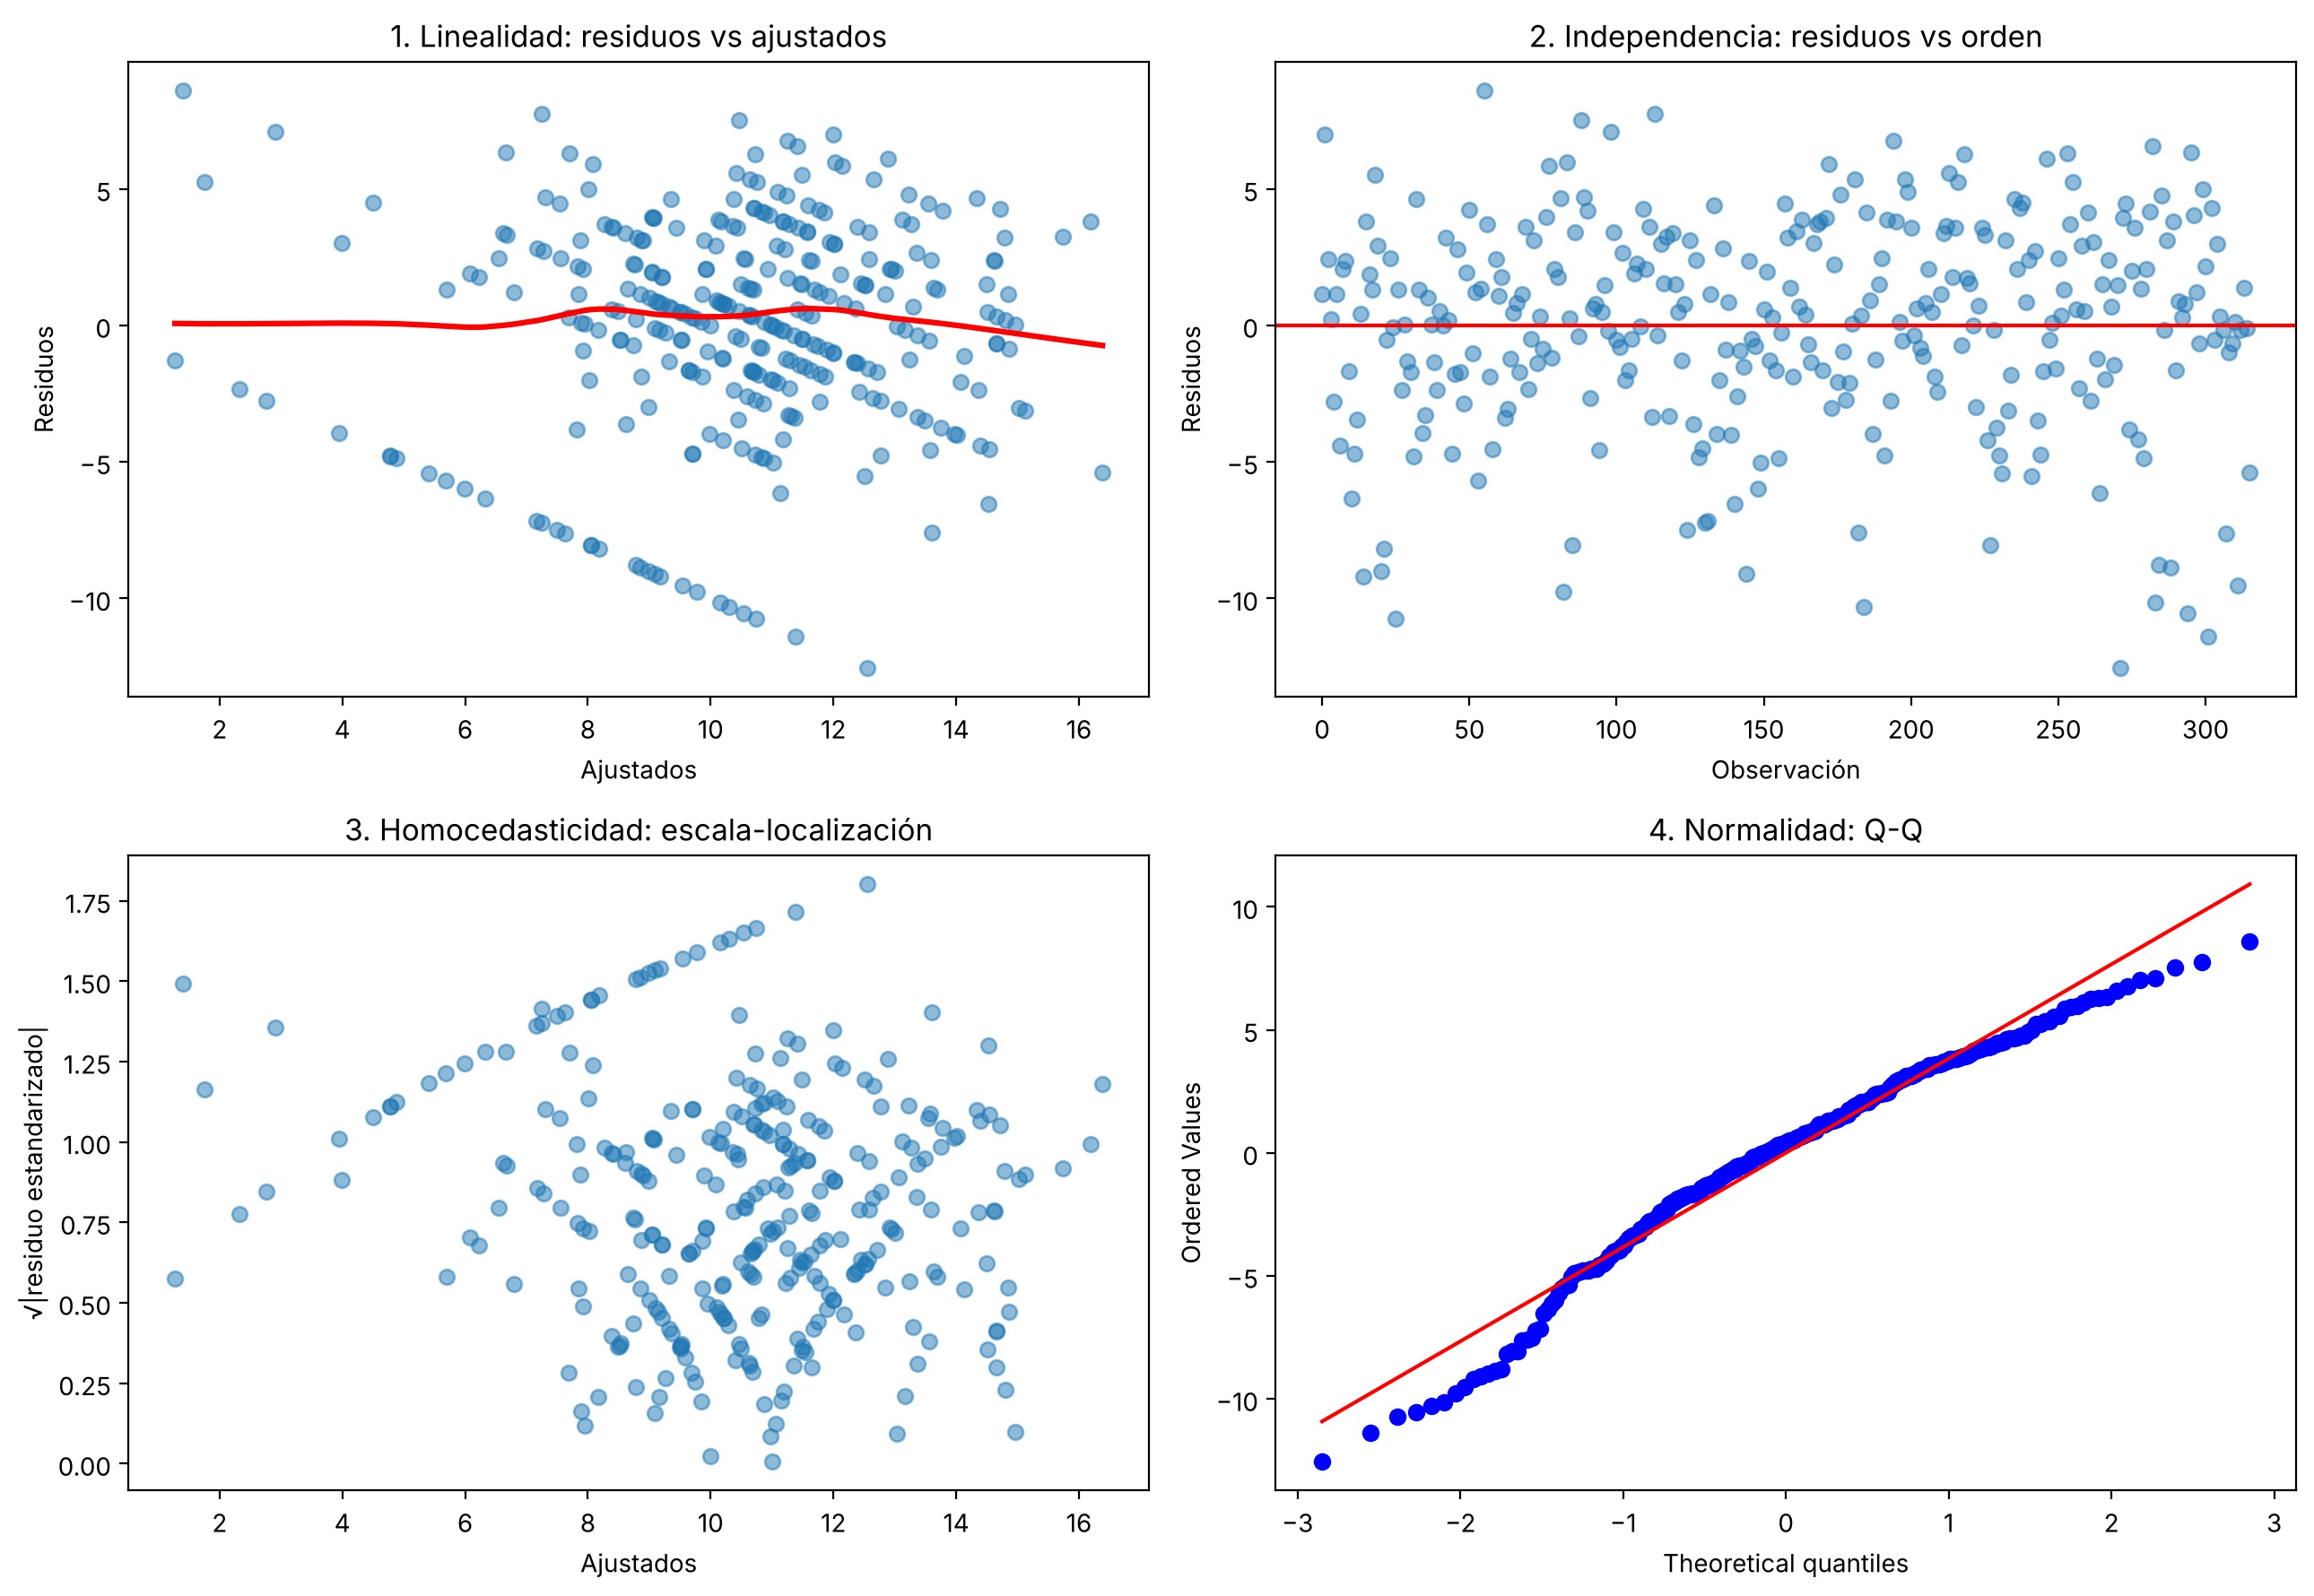

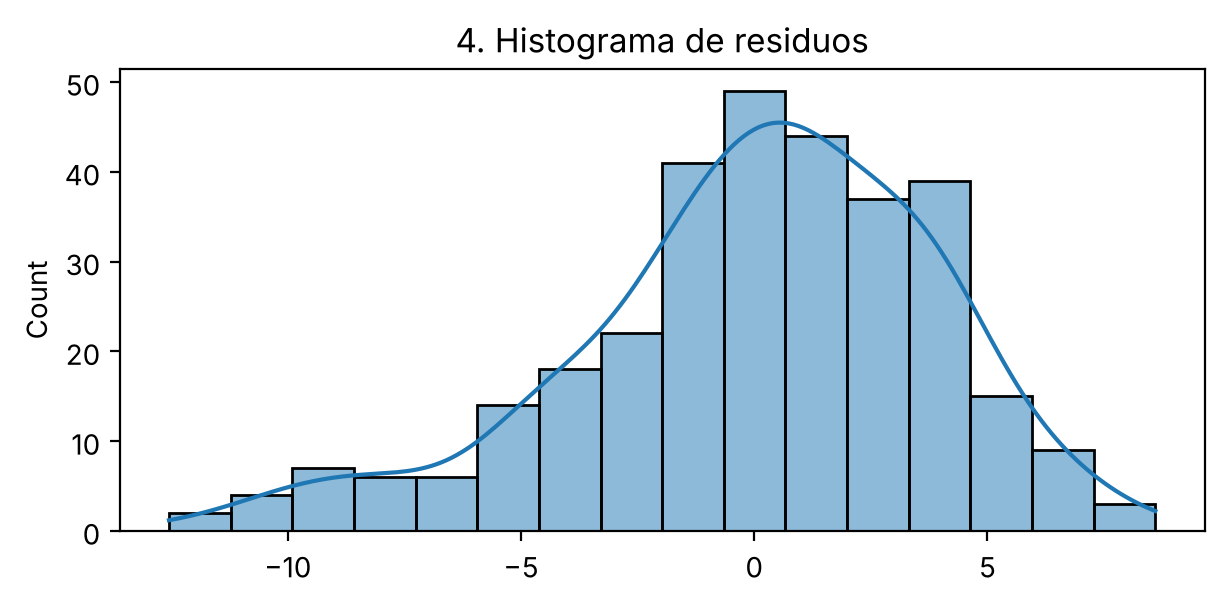

1. Linealidad       - Ramsey RESET p = 0.47
2. Independencia    - Durbin-Watson  = 2.015
3. Homocedasticidad - Breusch-Pagan p = 0.2232
4. Normalidad       - Shapiro-Wilk W = 0.9700, p = 3.865e-06


In [9]:
# 3.4 Supuestos del Modelo B. Se evalúan con los residuos de ENTRENAMIENTO (datos con que se ajustó)
prep = modelos['B'].named_steps['preprocessor']
nombres = [n.split('__')[1] for n in prep.get_feature_names_out()]
X_dis = sm.add_constant(pd.DataFrame(prep.transform(train[feat_B]), columns=nombres))
ols = sm.OLS(y_train.to_numpy(), X_dis).fit()
res, aj = ols.resid, ols.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.regplot(x=aj, y=res, lowess=True, ax=ax[0, 0], scatter_kws={'alpha': .5}, line_kws={'color': 'red'})
ax[0, 0].set(title='1. Linealidad: residuos vs ajustados', xlabel='Ajustados', ylabel='Residuos')
ax[0, 1].plot(np.asarray(res), 'o', alpha=.5); ax[0, 1].axhline(0, color='red')
ax[0, 1].set(title='2. Independencia: residuos vs orden', xlabel='Observación', ylabel='Residuos')
ax[1, 0].scatter(aj, np.sqrt(np.abs(res / res.std())), alpha=.5)
ax[1, 0].set(title='3. Homocedasticidad: escala-localización', xlabel='Ajustados', ylabel='√|residuo estandarizado|')
stats.probplot(res, plot=ax[1, 1]); ax[1, 1].set_title('4. Normalidad: Q-Q')
plt.tight_layout(); plt.show()
plt.figure(figsize=(7, 3)); sns.histplot(res, kde=True); plt.title('4. Histograma de residuos'); plt.show()

reset = linear_reset(ols, power=2, use_f=True)
dw = durbin_watson(res)
bp_p = het_breuschpagan(res, X_dis)[1]
sw = stats.shapiro(res)
print(f'1. Linealidad       - Ramsey RESET p = {float(reset.pvalue):.4g}')
print(f'2. Independencia    - Durbin-Watson  = {dw:.3f}')
print(f'3. Homocedasticidad - Breusch-Pagan p = {bp_p:.4g}')
print(f'4. Normalidad       - Shapiro-Wilk W = {sw.statistic:.4f}, p = {sw.pvalue:.4g}')

In [10]:
# 5. No multicolinealidad: VIF sobre la matriz de diseño del Modelo B
vif = pd.Series([variance_inflation_factor(X_dis.values, i) for i in range(1, X_dis.shape[1])],
                index=X_dis.columns[1:]).sort_values(ascending=False)
print(vif.head(12).round(2).to_string())
print(f'\nVIF máximo: {vif.max():.2f} | Variables con VIF > 5: {(vif > 5).sum()} | VIF > 10: {(vif > 10).sum()}')

Fjob_other       6.14
Fjob_services    5.23
Mjob_teacher     3.14
Medu             2.91
Fjob_teacher     2.76
Mjob_services    2.71
Mjob_other       2.60
Walc             2.45
Mjob_health      2.36
Fedu             2.17
Fjob_health      2.12
Dalc             2.09

VIF máximo: 6.14 | Variables con VIF > 5: 2 | VIF > 10: 0


| Supuesto | Evidencia | Conclusión |
|---|---|---|
| Linealidad | Gráfico de residuos; RESET p = 0.47 | La prueba no detecta mala especificación |
| Independencia | Durbin-Watson = 2.015 | No se observa autocorrelación de primer orden. El orden de las filas no es temporal, así que también depende del muestreo |
| Homocedasticidad | Gráfico escala-localización; Breusch-Pagan p = 0.223 | No se rechaza varianza constante. Las notas en 0 forman un patrón visible en el límite inferior |
| Normalidad | Q-Q, histograma; Shapiro-Wilk p < 0.001 | **No se cumple**; influyen las notas en 0 |
| No multicolinealidad | VIF máximo = 6.14; dos variables sobre 5, ninguna sobre 10 | Multicolinealidad moderada en dummies de `Fjob`; no es severa |

No rechazar una hipótesis no demuestra que el supuesto sea cierto. La falta de normalidad afecta sobre todo a los intervalos y pruebas de significancia.

### 3.5 Pregunta crítica: fuga de datos
La **fuga de datos** ocurre cuando el modelo usa información que no estará disponible en el momento real de la predicción (o información de prueba durante el entrenamiento), y por eso su desempeño parece mejor de lo que será en ese uso. G2 solo se conoce al terminar el segundo período. Si la institución quiere intervenir **antes**, el Modelo A usa información del futuro respecto a esa decisión.

El Modelo A no es inútil: si la predicción se hace **después** de publicar G2, esas notas son válidas y todavía podría apoyar una intervención tardía. Para **alerta temprana**, el planteamiento correcto es el Modelo B. Sin embargo, con R² = 0.036 **no recomendamos usarlo para decisiones individuales**: antes hacen falta más datos y mejores variables disponibles al inicio del curso. `absences` y otras variables también deben medirse solo hasta la fecha de predicción.

## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.

> **Pendiente del grupo:** agregar en APA 7 las fuentes que realmente hayan consultado en la biblioteca de la Universidad.

## Declaración de uso de inteligencia artificial
Se utilizó Claude (Anthropic) para revisar el notebook frente a la guía, corregir y completar el código, ejecutarlo y redactar un borrador de las interpretaciones y conclusiones. El grupo debe revisar el contenido, redactar las respuestas con sus propias palabras y poder explicar cada línea en la defensa.